# 🤖 ChurnGuard AI — 3 : Modélisation, valeur business et équité

Les notebooks 1 et 2 ont préparé les données. Ce notebook répond à quatre questions :

1. **Quel modèle** prédit le mieux qui va partir ?
2. **Quels clients contacter** en priorité, et combien cela rapporte-t-il ?
3. **Pourquoi** un client est jugé à risque (explicabilité) ?
4. **Le modèle est-il équitable** entre les groupes (genre, seniors) ?

### 🧭 Plan
| # | Section | Question |
|---|---|---|
| 0 | Configuration | Chargement des données préparées |
| 1 | Comment mesurer la qualité | Quelles métriques, et pourquoi pas l'accuracy ? |
| 2 | Comparaison des modèles | Lequel est le meilleur en validation croisée ? |
| 3 | Réglage du meilleur modèle | Peut-on l'améliorer ? |
| 4 | Modèle final et calibration | Les probabilités sont-elles fiables ? |
| 5 | Évaluation sur le test | Performance sur des clients jamais vus |
| 6 | Valeur business | Qui contacter, pour quel gain net ? |
| 7 | Explicabilité | Pourquoi ce client est-il à risque ? |
| 8 | Audit d'équité | Les groupes sont-ils traités de façon comparable ? |
| 9 | Export | Modèle, carte du modèle, prédictions |
| 10 | Synthèse | Bilan |

> **Règle d'or :** le jeu de test n'est utilisé **qu'une seule fois**, à la section 5. Tous les choix (modèle, réglages, calibration) sont faits **sur le train** par validation croisée.

## 0. Configuration & chargement

In [1]:
import warnings, os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib, sklearn
from sklearn.model_selection import StratifiedKFold, ParameterGrid, ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from IPython.display import display, Markdown

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sns.set_theme(style='whitegrid', context='notebook')
C_STAY, C_CHURN, C_MAIN, C_GREY = '#2A9D8F', '#E76F51', '#264653', '#8D99AE'
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})

SEED, N_FOLDS, N_SEARCH = 42, 5, 12

def h(text):
    display(Markdown(text))

print('SHAP disponible :', HAS_SHAP, '' if HAS_SHAP else '(installer avec : pip install shap ; sinon on utilise l\'importance par permutation)')

c:\Users\pc\Desktop\DATA\Hackathon_churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP disponible : True 


In [2]:
# --- Données préparées par le notebook 2 -----------------------------------------
def find_processed():
    for base in ['data/processed', '../data/processed', '../../data/processed']:
        if os.path.exists(f'{base}/X_train_scaled.csv'):
            return Path(base).resolve()
    raise FileNotFoundError('data/processed/X_train_scaled.csv introuvable : exécute d\'abord le notebook 2.')

DATA = find_processed()
ROOT = DATA.parents[1]
MODELS_DIR = ROOT / 'models'
MODELS_DIR.mkdir(exist_ok=True)

Xtr_s, Xte_s = pd.read_csv(DATA / 'X_train_scaled.csv'), pd.read_csv(DATA / 'X_test_scaled.csv')   # avec mise à l'échelle
Xtr_t, Xte_t = pd.read_csv(DATA / 'X_train_tree.csv'),   pd.read_csv(DATA / 'X_test_tree.csv')     # sans mise à l'échelle
ytr, yte = pd.read_csv(DATA / 'y_train.csv'), pd.read_csv(DATA / 'y_test.csv')
y_train, y_test = ytr['Churn'].values, yte['Churn'].values
audit_test = pd.read_csv(DATA / 'audit_sensitive_test.csv')            # gender, SeniorCitizen (jamais utilisés par le modèle)
monthly_test = pd.read_csv(DATA / 'test_features.csv')['MonthlyCharges'].values

print(f'Train : {Xtr_s.shape[0]:,} clients × {Xtr_s.shape[1]} variables   |   Test : {Xte_s.shape[0]:,} clients')
print(f'Taux de churn : train {y_train.mean():.2%}   |   test {y_test.mean():.2%}')
print(f'Dossier des modèles : {MODELS_DIR}')

Train : 5,634 clients × 32 variables   |   Test : 1,409 clients
Taux de churn : train 26.54%   |   test 26.54%
Dossier des modèles : C:\Users\pc\Desktop\DATA\Hackathon_churn\models


---
## 1. Comment mesurer la qualité du modèle
Un modèle qui répond toujours « personne ne part » aurait **73 % de bonnes réponses** et ne servirait à rien. L'**accuracy** est donc trompeuse. On utilise des métriques adaptées au déséquilibre :

| Métrique | Question à laquelle elle répond | Valeur « hasard » |
|---|---|---|
| **PR-AUC** *(métrique principale)* | Parmi les clients que le modèle classe en haut, quelle part part vraiment ? | = taux de churn (≈ 0,27) |
| **ROC-AUC** | Le modèle classe-t-il un client parti au-dessus d'un client resté ? | 0,5 |
| **Rappel** | Parmi les clients qui partent, combien en détecte-t-on ? | |
| **Précision** | Parmi les clients signalés, combien partent vraiment ? | |
| **Brier** | Les probabilités annoncées sont-elles justes ? (plus petit = mieux) | |
| **Gains / lift** | Si on contacte les 20 % les plus à risque, quelle part des départs couvre-t-on ? | |

Le déséquilibre est géré par des **poids de classe** (un client parti compte plus à l'entraînement), puis par le **choix de la décision** selon la valeur business (section 6).

---
## 2. Comparaison des modèles
**Objectif :** choisir entre trois familles de modèles, de la plus simple à la plus puissante, avec une **validation croisée stratifiée à 5 plis** sur le train.

*Principe :* on coupe le train en 5 parties ; chaque partie sert à tour de rôle de « mini-test » pendant que le modèle apprend sur les 4 autres. On obtient ainsi pour **chaque client du train** une prédiction « honnête » (faite par un modèle qui ne l'a pas vu). Ces prédictions servent à comparer, régler et calibrer sans toucher au test.

| Modèle | Atout | Données utilisées |
|---|---|---|
| Régression logistique | Simple, très lisible | avec mise à l'échelle |
| Random Forest | Capte les interactions | sans mise à l'échelle |
| Gradient Boosting | Souvent le plus précis | sans mise à l'échelle |

,PR-AUC,PR-AUC ±,ROC-AUC,ROC-AUC ±
Régression logistique,0.661,0.013,0.846,0.011
Gradient Boosting,0.658,0.020,0.846,0.011
Random Forest,0.657,0.016,0.846,0.009
Hasard (référence),0.265,0.000,0.500,0.000


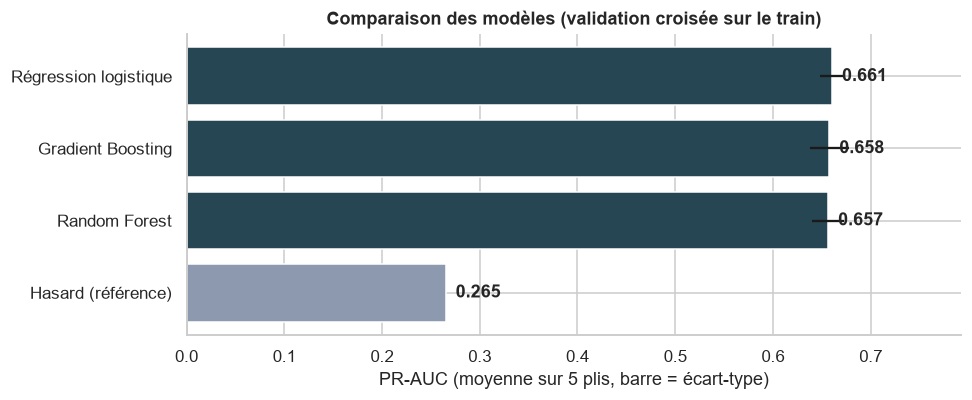

In [3]:
# --- Les trois familles de modèles, avec leurs réglages par défaut et leur espace de recherche -----
MODEL_DEFS = {
    'Régression logistique': {
        'make': lambda **p: LogisticRegression(max_iter=2000, class_weight='balanced', **p),
        'data': 'scaled',
        'default': {'C': 0.5},
        'space': {'C': [0.01, 0.03, 0.1, 0.3, 1, 3]},
    },
    'Random Forest': {
        'make': lambda **p: RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED, **p),
        'data': 'tree',
        'default': {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 8},
        'space': {'n_estimators': [200, 400], 'max_depth': [4, 6, 8, 12], 'min_samples_leaf': [3, 5, 10, 20],
                  'max_features': ['sqrt', 0.5]},
    },
    'Gradient Boosting': {
        'make': lambda **p: GradientBoostingClassifier(random_state=SEED, **p),
        'data': 'tree',
        'default': {'n_estimators': 150, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.8},
        'space': {'n_estimators': [100, 200, 300], 'learning_rate': [0.02, 0.05, 0.1], 'max_depth': [2, 3, 4],
                  'subsample': [0.7, 0.85, 1.0], 'min_samples_leaf': [5, 20, 50]},
    },
}
DATASETS = {'scaled': (Xtr_s, Xte_s), 'tree': (Xtr_t, Xte_t)}
cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)

def fit_model(model, X, y):
    # Le Gradient Boosting n'a pas de class_weight : on lui passe des poids par client (même idée).
    if isinstance(model, GradientBoostingClassifier):
        model.fit(X, y, sample_weight=compute_sample_weight('balanced', y))
    else:
        model.fit(X, y)
    return model

def cross_val_predict_proba(family, params):
    # Renvoie la probabilité "honnête" de chaque client du train + le score de chaque pli.
    spec = MODEL_DEFS[family]
    X, _ = DATASETS[spec['data']]
    oof = np.zeros(len(y_train))
    pr, roc = [], []
    for tr, va in cv.split(X, y_train):
        model = fit_model(spec['make'](**params), X.iloc[tr], y_train[tr])
        p = model.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        pr.append(average_precision_score(y_train[va], p))
        roc.append(roc_auc_score(y_train[va], p))
    return oof, pr, roc

cv_results, cv_oof = {}, {}
for name, spec in MODEL_DEFS.items():
    oof, pr, roc = cross_val_predict_proba(name, spec['default'])
    cv_oof[name] = oof
    cv_results[name] = {'PR-AUC': np.mean(pr), 'PR-AUC ±': np.std(pr), 'ROC-AUC': np.mean(roc), 'ROC-AUC ±': np.std(roc)}

cv_table = pd.DataFrame(cv_results).T.sort_values('PR-AUC', ascending=False)
cv_table.loc['Hasard (référence)'] = [y_train.mean(), 0, 0.5, 0]
display(cv_table)

plot = cv_table.sort_values('PR-AUC')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(plot.index, plot['PR-AUC'], xerr=plot['PR-AUC ±'], color=[C_GREY if 'Hasard' in i else C_MAIN for i in plot.index])
for i, v in enumerate(plot['PR-AUC']):
    ax.text(v + .01, i, f'{v:.3f}', va='center', fontweight='bold')
ax.set_xlim(0, plot['PR-AUC'].max() * 1.2); ax.set_xlabel('PR-AUC (moyenne sur 5 plis, barre = écart-type)')
ax.set_title('Comparaison des modèles (validation croisée sur le train)')
plt.tight_layout(); plt.show()

---
## 3. Réglage du meilleur modèle
**Objectif :** améliorer le gagnant de la section 2 en testant **jusqu'à 12 combinaisons de réglages** tirées au hasard (*random search*), toujours en validation croisée sur le train. Les réglages par défaut font partie des candidats : on ne garde un nouveau réglage que s'il fait mieux.

In [4]:
best_family = cv_table.drop('Hasard (référence)')['PR-AUC'].idxmax()
spec = MODEL_DEFS[best_family]
print(f'Modèle retenu pour le réglage : {best_family}')

n_iter = min(N_SEARCH, len(ParameterGrid(spec['space'])))
candidates = [spec['default']] + list(ParameterSampler(spec['space'], n_iter=n_iter, random_state=SEED))

search = []
for params in candidates:
    oof, pr, roc = cross_val_predict_proba(best_family, params)
    search.append({'réglages': params, 'PR-AUC': np.mean(pr), 'ROC-AUC': np.mean(roc), '_oof': oof})

search_df = pd.DataFrame(search).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
best_params, best_oof = search_df.loc[0, 'réglages'], search_df.loc[0, '_oof']
default_score = [s['PR-AUC'] for s in search if s['réglages'] == spec['default']][0]

h(f'**Top 5 des réglages testés ({len(candidates)} au total)**')
display(search_df[['réglages', 'PR-AUC', 'ROC-AUC']].head(5))
print(f'Réglage par défaut : PR-AUC {default_score:.3f}   →   meilleur réglage : PR-AUC {search_df.loc[0, "PR-AUC"]:.3f}')
print('Réglages retenus :', best_params)

Modèle retenu pour le réglage : Régression logistique


**Top 5 des réglages testés (7 au total)**

,réglages,PR-AUC,ROC-AUC
0,{'C': 0.1},0.661,0.847
1,{'C': 0.03},0.661,0.846
2,{'C': 0.3},0.661,0.846
3,{'C': 1},0.661,0.846
4,{'C': 0.5},0.661,0.846


Réglage par défaut : PR-AUC 0.661   →   meilleur réglage : PR-AUC 0.661
Réglages retenus : {'C': 0.1}


---
## 4. Modèle final et calibration des probabilités
**Pourquoi calibrer ?** Les poids de classe « gonflent » les probabilités : un modèle peut annoncer 60 % de risque alors que 35 % seulement des clients concernés partent vraiment. Or la valeur business (section 6) **multiplie la probabilité par un montant** : elle doit être juste.

**Comment :** on apprend une correction simple (*calibration de Platt*, une petite régression logistique) qui relie les probabilités « honnêtes » de la validation croisée à la réalité. Cette correction **conserve exactement le classement** des clients (donc ROC-AUC et PR-AUC ne changent pas) : elle ne fait que rendre les probabilités fiables.

In [5]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p)).reshape(-1, 1)

# 1) Modèle final : entraîné sur TOUT le train avec les meilleurs réglages
Xtr_best, Xte_best = DATASETS[spec['data']]
final_model = fit_model(spec['make'](**best_params), Xtr_best, y_train)

# 2) Correction apprise sur les prédictions honnêtes du train (jamais sur le test)
calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(logit(best_oof), y_train)

def calibrate(p_raw):
    return calibrator.predict_proba(logit(p_raw))[:, 1]

print(f'Modèle final : {best_family}')
print(f'Probabilité moyenne sur le train — avant calibration : {best_oof.mean():.3f}   après : {calibrate(best_oof).mean():.3f}   réalité : {y_train.mean():.3f}')

Modèle final : Régression logistique
Probabilité moyenne sur le train — avant calibration : 0.414   après : 0.265   réalité : 0.265


---
## 5. Évaluation sur le jeu de test
**Objectif :** mesurer la performance sur des clients que le modèle n'a **jamais vus**. C'est la seule utilisation du test.

In [6]:
p_raw = final_model.predict_proba(Xte_best)[:, 1]      # probabilités brutes du modèle
p_cal = calibrate(p_raw)                                # probabilités calibrées (à utiliser pour décider)

metrics = pd.DataFrame({
    'validation croisée (train)': [average_precision_score(y_train, best_oof), roc_auc_score(y_train, best_oof), brier_score_loss(y_train, calibrate(best_oof))],
    'test': [average_precision_score(y_test, p_cal), roc_auc_score(y_test, p_cal), brier_score_loss(y_test, p_cal)],
    'hasard': [y_test.mean(), 0.5, brier_score_loss(y_test, np.full(len(y_test), y_test.mean()))],
}, index=['PR-AUC', 'ROC-AUC', 'Brier (plus petit = mieux)'])
display(metrics)
print(f'Brier du test avant calibration : {brier_score_loss(y_test, p_raw):.3f}   après : {brier_score_loss(y_test, p_cal):.3f}')
print('Lecture : des scores proches entre validation croisée et test signalent un modèle stable (pas de sur-apprentissage).')

,validation croisée (train),test,hasard
PR-AUC,0.659,0.636,0.265
ROC-AUC,0.846,0.841,0.500
Brier (plus petit = mieux),0.135,0.139,0.195


Brier du test avant calibration : 0.167   après : 0.139
Lecture : des scores proches entre validation croisée et test signalent un modèle stable (pas de sur-apprentissage).


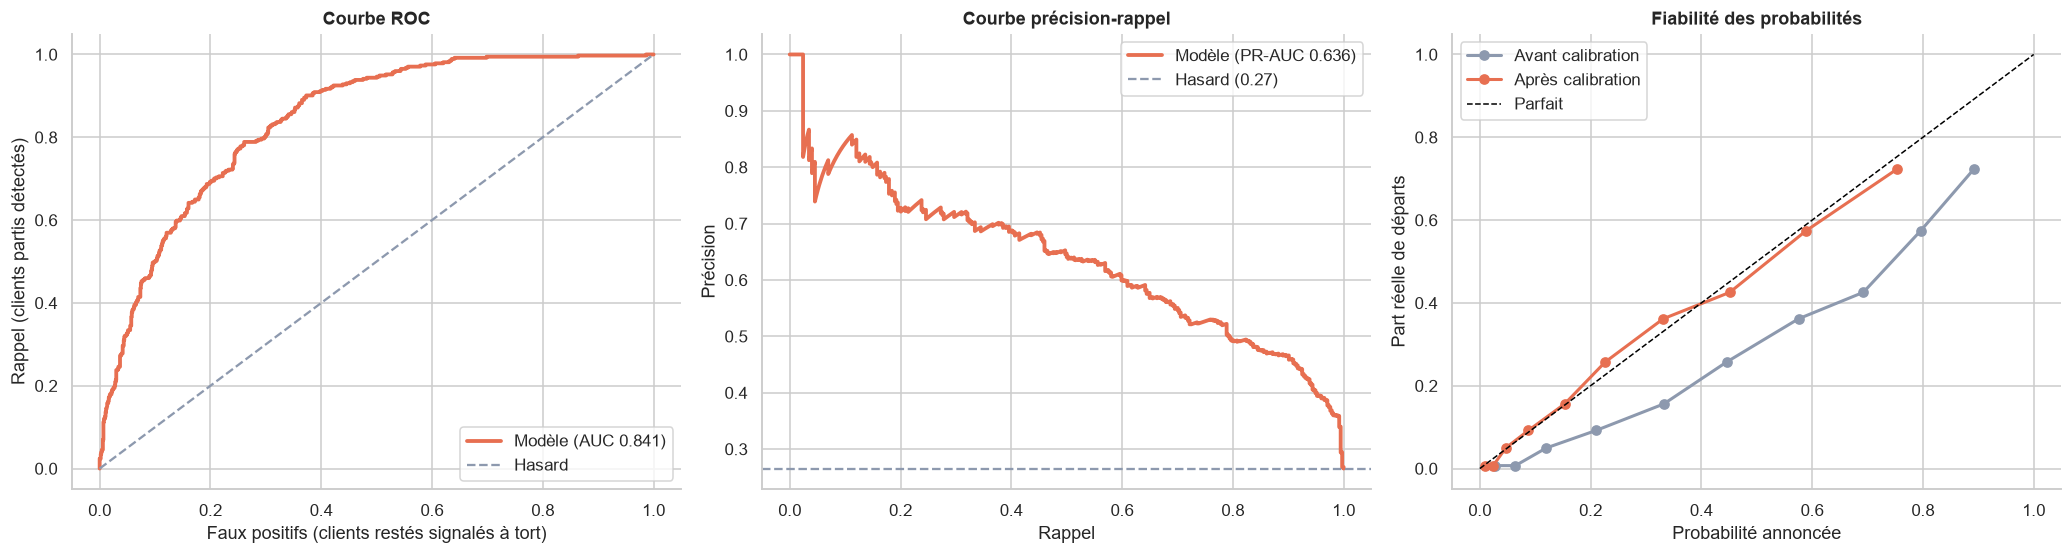

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

fpr, tpr, _ = roc_curve(y_test, p_cal)
axes[0].plot(fpr, tpr, color=C_CHURN, lw=2.5, label=f'Modèle (AUC {roc_auc_score(y_test, p_cal):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color=C_GREY, label='Hasard')
axes[0].set_xlabel('Faux positifs (clients restés signalés à tort)'); axes[0].set_ylabel('Rappel (clients partis détectés)')
axes[0].set_title('Courbe ROC'); axes[0].legend(loc='lower right')

prec, rec, _ = precision_recall_curve(y_test, p_cal)
axes[1].plot(rec, prec, color=C_CHURN, lw=2.5, label=f'Modèle (PR-AUC {average_precision_score(y_test, p_cal):.3f})')
axes[1].axhline(y_test.mean(), ls='--', color=C_GREY, label=f'Hasard ({y_test.mean():.2f})')
axes[1].set_xlabel('Rappel'); axes[1].set_ylabel('Précision'); axes[1].set_title('Courbe précision-rappel'); axes[1].legend()

for p, lab, col in [(p_raw, 'Avant calibration', C_GREY), (p_cal, 'Après calibration', C_CHURN)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    axes[2].plot(mean_p, frac, 'o-', color=col, lw=2, label=lab)
axes[2].plot([0, 1], [0, 1], '--', color='black', lw=1, label='Parfait')
axes[2].set_xlabel('Probabilité annoncée'); axes[2].set_ylabel('Part réelle de départs')
axes[2].set_title('Fiabilité des probabilités'); axes[2].legend()
plt.tight_layout(); plt.show()

### Gains : si on contacte les clients les plus à risque en premier

,nombre,départs couverts,lift (vs hasard)
clients contactés,,,
10% les plus à risque,140,0.273,2.727
20% les plus à risque,281,0.489,2.447
30% les plus à risque,422,0.650,2.166
50% les plus à risque,704,0.882,1.765


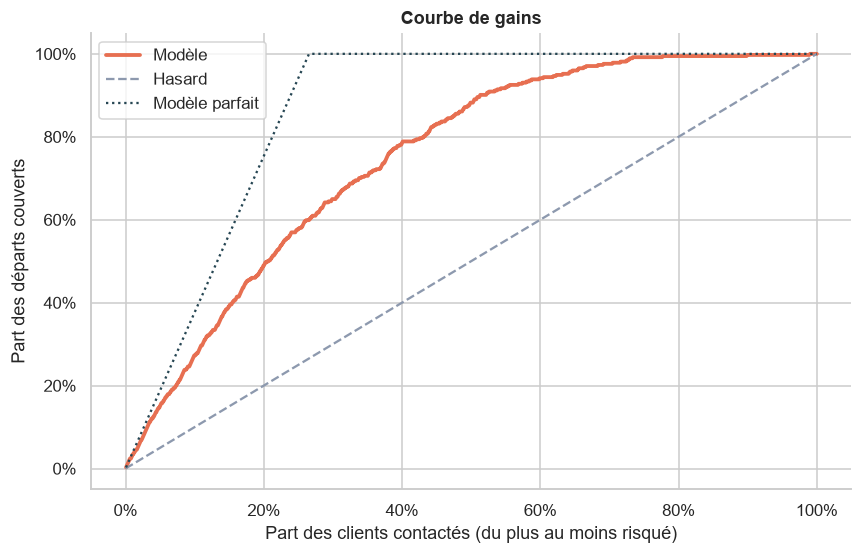

In [8]:
h('### Gains : si on contacte les clients les plus à risque en premier')
order = np.argsort(-p_cal)
cum_churn = np.cumsum(y_test[order]) / y_test.sum()
share = np.arange(1, len(y_test) + 1) / len(y_test)

rows = []
for q in [.10, .20, .30, .50]:
    k = int(q * len(y_test))
    rows.append({'clients contactés': f'{q:.0%} les plus à risque', 'nombre': k, 'départs couverts': cum_churn[k - 1],
                 'lift (vs hasard)': cum_churn[k - 1] / q})
display(pd.DataFrame(rows).set_index('clients contactés'))

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.plot(share, cum_churn, color=C_CHURN, lw=2.5, label='Modèle')
ax.plot([0, 1], [0, 1], '--', color=C_GREY, label='Hasard')
perfect = np.minimum(share / y_test.mean(), 1)
ax.plot(share, perfect, ':', color=C_MAIN, label='Modèle parfait')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Part des clients contactés (du plus au moins risqué)'); ax.set_ylabel('Part des départs couverts')
ax.set_title('Courbe de gains'); ax.legend()
plt.tight_layout(); plt.show()

---
## 6. Valeur business : qui contacter ?
**Objectif :** transformer des probabilités en **décisions rentables**. Contacter un client coûte de l'argent : il ne faut le faire que si le gain attendu dépasse le coût.

### Hypothèses (à ajuster avec les vraies données de l'entreprise)
Ces trois chiffres sont des **hypothèses de travail**, pas des données du jeu. Ils sont à présenter comme telles dans le pitch.

| Paramètre | Valeur | Signification |
|---|---|---|
| `COST_CONTACT` | 50 | Coût d'une action de rétention (remise, appel), dans la même unité que MonthlyCharges |
| `SUCCESS_RATE` | 30 % | Part des clients à risque effectivement retenus quand on les contacte |
| `HORIZON_MONTHS` | 12 | Nombre de mois de facturation sauvés si le client reste (on raisonne en revenu, pas en marge) |

### Règle de décision
On contacte un client si :  **probabilité de départ × taux de succès × (facture mensuelle × horizon) > coût du contact**

Cette règle tient compte à la fois du **risque** et de la **valeur** du client : un client à risque moyen mais à forte facture peut passer devant un client très risqué à faible facture.

,clients contactés,part contactée,départs couverts,gain net
stratégie,,,,
Ne rien faire,0,0.000,0.000,0.000
Contacter tout le monde,1409,1.000,1.000,"27,523.640"
Contacter si probabilité ≥ 50 %,292,0.207,0.500,"38,564.620"
Contacter les 20 % les plus à risque,282,0.200,0.489,"38,019.720"
Règle de valeur attendue (ChurnGuard),628,0.446,0.797,"53,338.060"
Idéal : contacter uniquement les futurs partants,374,0.265,1.000,"79,273.640"


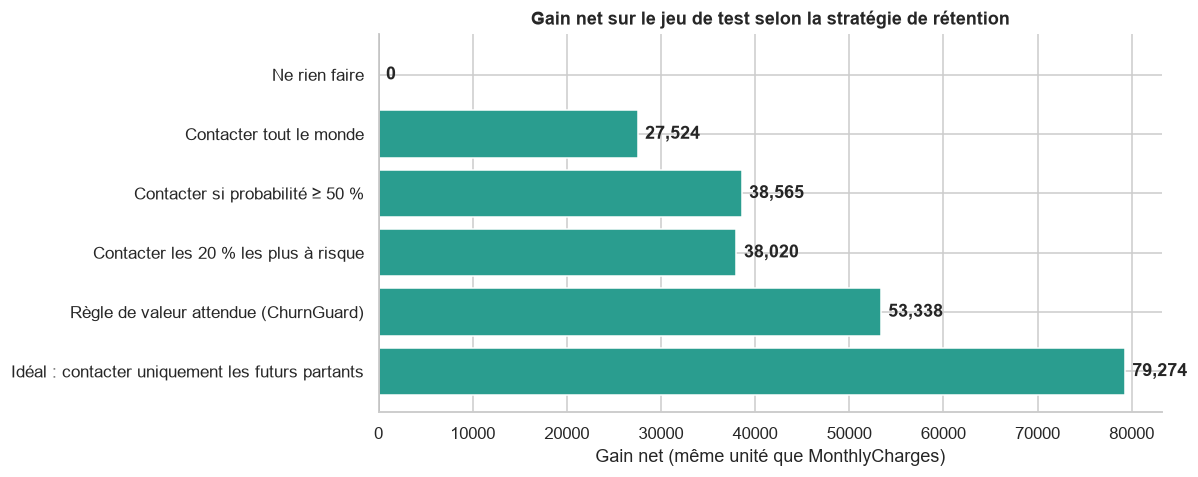

In [9]:
COST_CONTACT   = 50.0
SUCCESS_RATE   = 0.30
HORIZON_MONTHS = 12

value = monthly_test * HORIZON_MONTHS           # revenu sauvé si on retient le client

def decide(p, success=SUCCESS_RATE):
    # True = on contacte le client
    return p * success * value > COST_CONTACT

def net_value(treat, success=SUCCESS_RATE):
    # Gain net attendu : on ne gagne que si le client partait vraiment (y_test = 1), on paie le contact dans tous les cas
    return float((treat * (y_test * success * value - COST_CONTACT)).sum())

treat_rule = decide(p_cal)
strategies = {
    'Ne rien faire': np.zeros(len(y_test), dtype=bool),
    'Contacter tout le monde': np.ones(len(y_test), dtype=bool),
    'Contacter si probabilité ≥ 50 %': p_cal >= 0.5,
    'Contacter les 20 % les plus à risque': p_cal >= np.quantile(p_cal, .8),
    'Règle de valeur attendue (ChurnGuard)': treat_rule,
    'Idéal : contacter uniquement les futurs partants': y_test == 1,
}
rows = []
for name, t in strategies.items():
    rows.append({'stratégie': name, 'clients contactés': int(t.sum()), 'part contactée': t.mean(),
                 'départs couverts': (t & (y_test == 1)).sum() / y_test.sum(), 'gain net': net_value(t)})
strat_df = pd.DataFrame(rows).set_index('stratégie')
display(strat_df)

plot = strat_df['gain net'].iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(plot.index, plot.values, color=[C_STAY if v >= 0 else C_CHURN for v in plot.values])
for i, v in enumerate(plot.values):
    ax.text(v + (abs(plot).max() * .01 if v >= 0 else -abs(plot).max() * .01), i, f'{v:,.0f}', va='center', ha='left' if v >= 0 else 'right', fontweight='bold')
ax.axvline(0, color='black', lw=1); ax.set_title('Gain net sur le jeu de test selon la stratégie de rétention')
ax.set_xlabel('Gain net (même unité que MonthlyCharges)')
plt.tight_layout(); plt.show()

### Robustesse : et si le taux de succès réel était différent ?

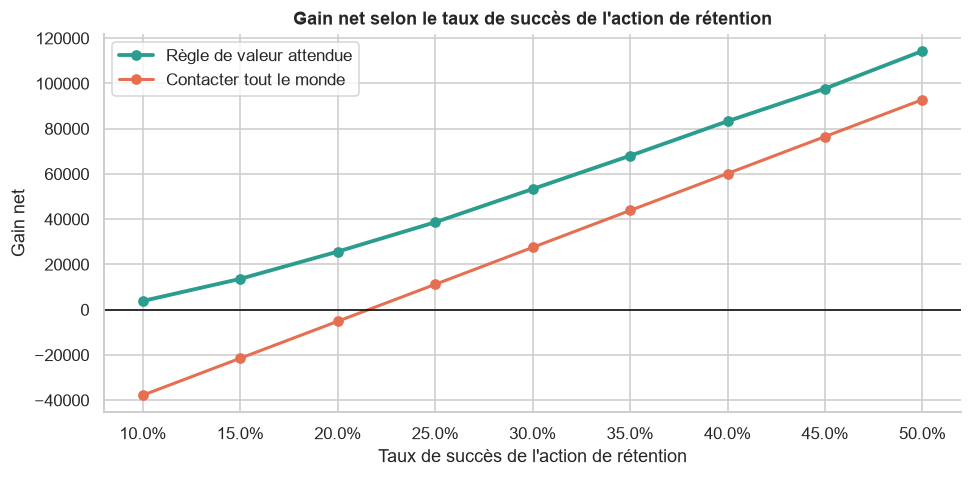

In [10]:
h('### Robustesse : et si le taux de succès réel était différent ?')
rates = np.linspace(.1, .5, 9)
rule_gain = [net_value(decide(p_cal, s), s) for s in rates]
all_gain = [net_value(np.ones(len(y_test), dtype=bool), s) for s in rates]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rates, rule_gain, 'o-', color=C_STAY, lw=2.5, label='Règle de valeur attendue')
ax.plot(rates, all_gain, 'o-', color=C_CHURN, lw=2, label='Contacter tout le monde')
ax.axhline(0, color='black', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel('Taux de succès de l\'action de rétention')
ax.set_ylabel('Gain net'); ax.set_title('Gain net selon le taux de succès de l\'action de rétention'); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
h('### Niveaux de risque (pour la priorisation dans Salesforce)')
TIER_HIGH, TIER_MID = 0.50, 0.25
tier = np.where(p_cal >= TIER_HIGH, 'Élevé', np.where(p_cal >= TIER_MID, 'Moyen', 'Faible'))

tier_df = pd.DataFrame({'niveau': tier, 'churn réel': y_test, 'probabilité prédite': p_cal}).groupby('niveau').agg(
    clients=('churn réel', 'size'), churn_réel=('churn réel', 'mean'), probabilité_moyenne_prédite=('probabilité prédite', 'mean'))
display(tier_df.reindex(['Élevé', 'Moyen', 'Faible']))
print(f'Élevé : probabilité ≥ {TIER_HIGH:.0%}   |   Moyen : {TIER_MID:.0%} à {TIER_HIGH:.0%}   |   Faible : < {TIER_MID:.0%}')
print('Lecture : les niveaux sont cohérents si le churn réel augmente de Faible à Élevé et reste proche de la probabilité prédite.')

### Niveaux de risque (pour la priorisation dans Salesforce)

,clients,churn_réel,probabilité_moyenne_prédite
niveau,,,
Élevé,292,0.640,0.666
Moyen,310,0.358,0.371
Faible,807,0.094,0.083


Élevé : probabilité ≥ 50%   |   Moyen : 25% à 50%   |   Faible : < 25%
Lecture : les niveaux sont cohérents si le churn réel augmente de Faible à Élevé et reste proche de la probabilité prédite.


---
## 7. Explicabilité : pourquoi ce client est-il à risque ?
**Objectif :** ouvrir la « boîte noire ». Un conseiller ne contactera un client que s'il comprend la raison.

**Méthode :** les valeurs **SHAP** attribuent à chaque variable sa part dans le score d'un client : positive = pousse vers le départ, négative = retient le client. Si la librairie `shap` n'est pas installée, on utilise à la place l'**importance par permutation** (on mélange une variable et on mesure la perte de performance ; plus la perte est grande, plus la variable compte).

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


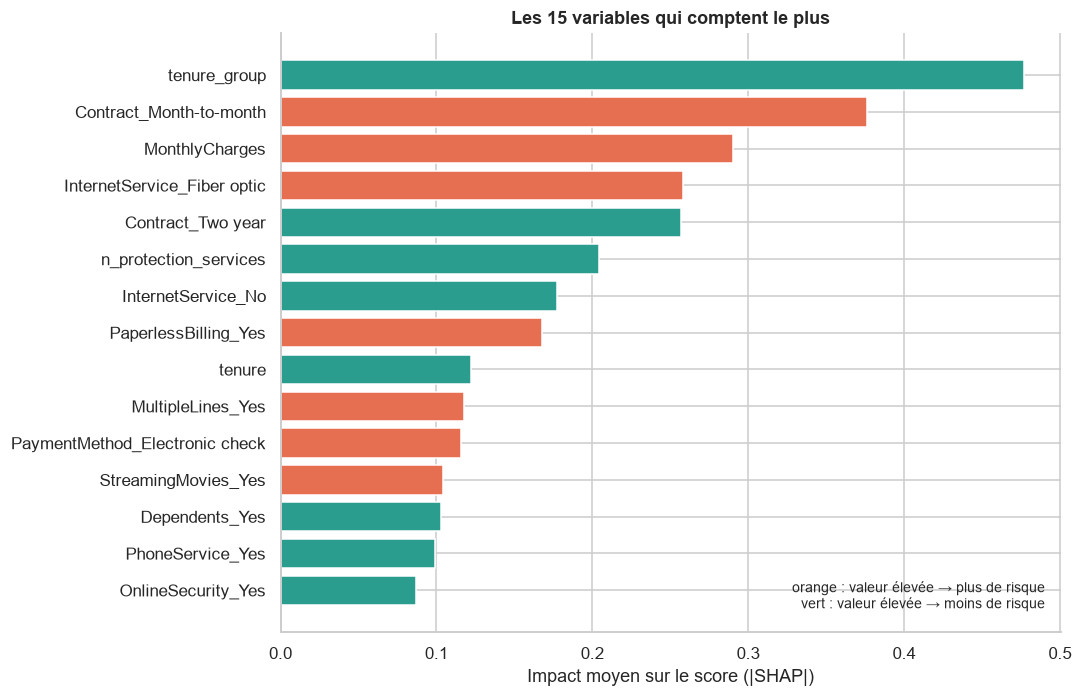

In [12]:
def shap_values_for(model, X, background):
    if isinstance(model, LogisticRegression):
        values = shap.LinearExplainer(model, background).shap_values(X)
    else:
        values = shap.TreeExplainer(model).shap_values(X)
    if isinstance(values, list):                 # certaines versions renvoient une liste par classe
        values = values[1]
    values = np.asarray(values)
    if values.ndim == 3:                         # ou un tableau (clients, variables, classes)
        values = values[:, :, 1]
    return values

sv = None
if HAS_SHAP:
    try:
        sv = shap_values_for(final_model, Xte_best, Xtr_best)
    except Exception as err:
        print('SHAP indisponible pour ce modèle, repli sur la permutation :', err)

cols = np.array(Xte_best.columns)
if sv is not None:
    importance = pd.Series(np.abs(sv).mean(axis=0), index=cols).sort_values(ascending=False)
    direction = pd.Series({c: (np.sign(np.corrcoef(Xte_best[c], sv[:, i])[0, 1]) if Xte_best[c].std() > 0 and sv[:, i].std() > 0 else 0)
                           for i, c in enumerate(cols)})
    label = 'Impact moyen sur le score (|SHAP|)'
else:
    perm = permutation_importance(final_model, Xte_best, y_test, scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=-1)
    importance = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False)
    direction = None
    label = 'Perte de PR-AUC quand la variable est mélangée'

top = importance.head(15).iloc[::-1]
colors = [C_CHURN if (direction is not None and direction[c] > 0) else C_STAY if direction is not None else C_MAIN for c in top.index]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top.index, top.values, color=colors)
ax.set_xlabel(label); ax.set_title('Les 15 variables qui comptent le plus')
if direction is not None:
    ax.text(.98, .04, 'orange : valeur élevée → plus de risque\nvert : valeur élevée → moins de risque', transform=ax.transAxes, ha='right', fontsize=9)
plt.tight_layout(); plt.show()

### Exemple : le client le plus à risque du test

Client 5178-LMXOP : probabilité de départ calibrée 87.3% ; a-t-il vraiment quitté ? oui


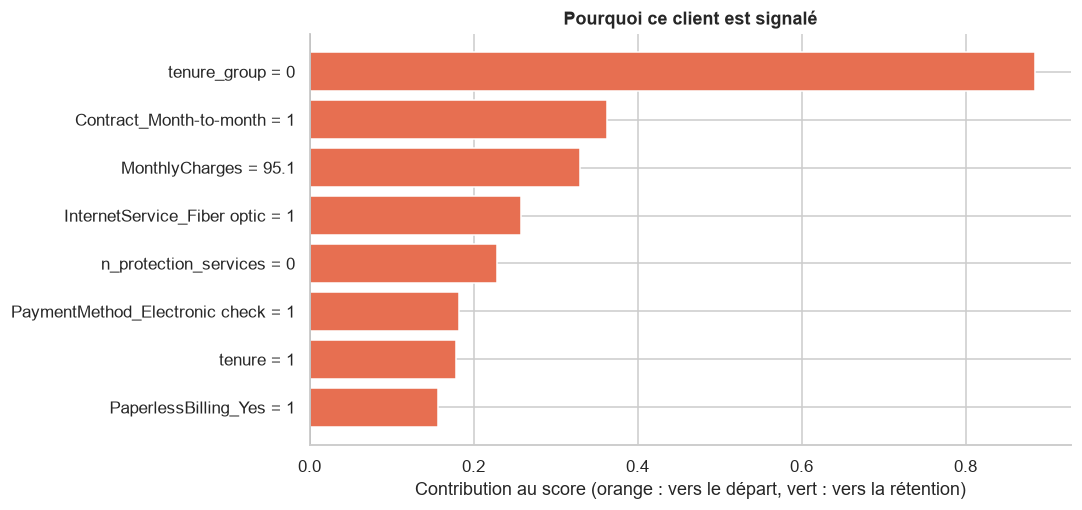

In [13]:
h('### Exemple : le client le plus à risque du test')
i = int(np.argmax(p_cal))
print(f'Client {yte.loc[i, "customerID"]} : probabilité de départ calibrée {p_cal[i]:.1%} ; a-t-il vraiment quitté ? {"oui" if y_test[i] == 1 else "non"}')
if sv is not None:
    contrib = pd.Series(sv[i], index=cols)
    shown = contrib.reindex(contrib.abs().sort_values(ascending=False).head(8).index).iloc[::-1]
    names = [f'{c} = {Xte_t.loc[i, c]:.3g}' if c in Xte_t.columns else c for c in shown.index]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.barh(names, shown.values, color=[C_CHURN if v > 0 else C_STAY for v in shown.values])
    ax.axvline(0, color='black', lw=1); ax.set_xlabel('Contribution au score (orange : vers le départ, vert : vers la rétention)')
    ax.set_title('Pourquoi ce client est signalé')
    plt.tight_layout(); plt.show()
else:
    display(Xte_t.loc[[i]].T.rename(columns={i: 'valeurs du client'}).head(15))
    print('Explication par client : installer shap pour obtenir les raisons personnalisées.')

---
## 8. Audit d'équité
**Objectif :** vérifier que le modèle ne traite pas un groupe de façon nettement différente. `gender` et `SeniorCitizen` ne sont **pas** des variables du modèle ; on les ajoute ici **uniquement pour mesurer**.

On compare, pour chaque groupe, la décision de la section 6 (contacter ou non) :

| Mesure | Question | Cible d'équité |
|---|---|---|
| **Rappel** | Parmi les clients qui partent vraiment, quelle part est détectée ? | Proche entre groupes (*égalité des chances*) |
| **Taux d'alerte** | Quelle part du groupe est signalée ? | Proche entre groupes, **sauf si le churn réel diffère** |
| **Faux positifs** | Quelle part des clients restés est signalée à tort ? | Proche entre groupes |

Repère indicatif : un rapport entre groupes compris entre **0,8 et 1,25** est jugé acceptable (règle des 4/5). Pour `SeniorCitizen`, le churn réel diffère déjà beaucoup (≈ 24 % contre ≈ 41 %) : un taux d'alerte plus élevé chez les seniors est donc **attendu** ; c'est le **rappel** qui compte.

In [14]:
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - half, c + half

def group_report(attr):
    rows = []
    for g in sorted(audit_test[attr].unique()):
        m = (audit_test[attr] == g).values
        yt, tr = y_test[m] == 1, treat_rule[m]
        tp, fn = int((tr & yt).sum()), int((~tr & yt).sum())
        fp, tn = int((tr & ~yt).sum()), int((~tr & ~yt).sum())
        lo, hi = wilson_interval(tp, tp + fn)
        rows.append({'groupe': g, 'clients': int(m.sum()), 'churn réel': yt.mean(), "taux d'alerte": tr.mean(),
                     'rappel': tp / max(tp + fn, 1), 'rappel IC95 bas': lo, 'rappel IC95 haut': hi,
                     'faux positifs': fp / max(fp + tn, 1), 'précision': tp / max(tp + fp, 1)})
    return pd.DataFrame(rows).set_index('groupe')

reports = {a: group_report(a) for a in ['gender', 'SeniorCitizen']}
for attr, rep in reports.items():
    h(f'### {attr}')
    display(rep)
    ref = rep['clients'].idxmax()
    ratio = pd.DataFrame({'rappel': rep['rappel'] / rep.loc[ref, 'rappel'],
                          "taux d'alerte": rep["taux d'alerte"] / rep.loc[ref, "taux d'alerte"],
                          'faux positifs': rep['faux positifs'] / rep.loc[ref, 'faux positifs']})
    display(ratio.rename_axis(f'rapport vs « {ref} »'))

### gender

,clients,churn réel,taux d'alerte,rappel,rappel IC95 bas,rappel IC95 haut,faux positifs,précision
groupe,,,,,,,,
Female,687,0.281,0.447,0.788,0.725,0.839,0.314,0.495
Male,722,0.251,0.445,0.807,0.743,0.858,0.323,0.455


,rappel,taux d'alerte,faux positifs
rapport vs « Male »,,,
Female,0.976,1.005,0.970
Male,1.000,1.000,1.000


### SeniorCitizen

,clients,churn réel,taux d'alerte,rappel,rappel IC95 bas,rappel IC95 haut,faux positifs,précision
groupe,,,,,,,,
No,1187,0.233,0.389,0.754,0.700,0.801,0.279,0.450
Yes,222,0.441,0.748,0.918,0.847,0.958,0.613,0.542


,rappel,taux d'alerte,faux positifs
rapport vs « No »,,,
No,1.000,1.000,1.000
Yes,1.219,1.921,2.198


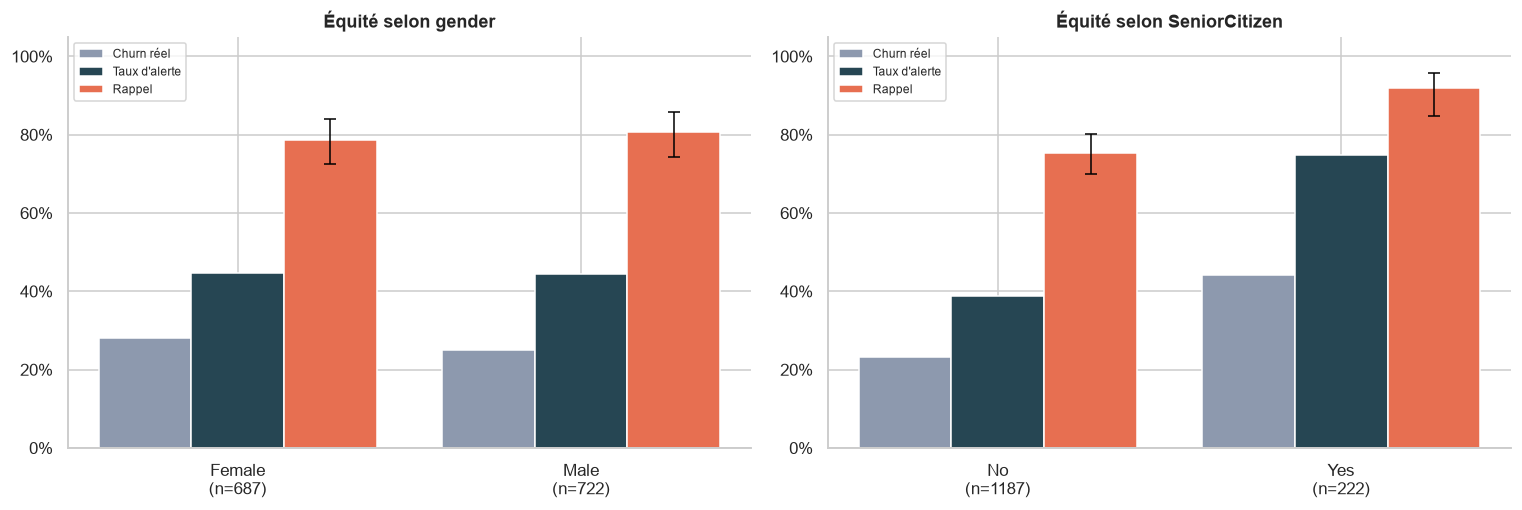

Lecture : des barres de rappel proches, avec des barres d'erreur qui se chevauchent, indiquent que le modèle détecte les départs de façon comparable dans chaque groupe.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (attr, rep) in zip(axes, reports.items()):
    x = np.arange(len(rep)); w = .27
    ax.bar(x - w, rep['churn réel'], w, color=C_GREY, label='Churn réel')
    ax.bar(x, rep["taux d'alerte"], w, color=C_MAIN, label="Taux d'alerte")
    ax.bar(x + w, rep['rappel'], w, color=C_CHURN, label='Rappel')
    err = np.vstack([(rep['rappel'] - rep['rappel IC95 bas']).clip(lower=0), (rep['rappel IC95 haut'] - rep['rappel']).clip(lower=0)])
    ax.errorbar(x + w, rep['rappel'], yerr=err, fmt='none', ecolor='black', capsize=4, lw=1)
    ax.set_xticks(x); ax.set_xticklabels([f'{g}\n(n={n})' for g, n in zip(rep.index, rep['clients'])])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 1.05)
    ax.set_title(f'Équité selon {attr}'); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()
print('Lecture : des barres de rappel proches, avec des barres d\'erreur qui se chevauchent, indiquent que le modèle détecte les départs de façon comparable dans chaque groupe.')

---
## 9. Export
**Objectif :** sauvegarder le modèle (dans `models/`), sa carte d'identité et les prédictions (dans `data/processed/`) pour les étapes suivantes (génération des messages de rétention, intégration Salesforce).

| Fichier | Contenu |
|---|---|
| `models/churn_model.joblib` | Modèle final + correction de calibration + liste des variables attendues |
| `models/model_card.json` | Carte du modèle : performances, réglages, hypothèses business, seuils |
| `data/processed/predictions_test.csv` | Pour chaque client du test : probabilité, niveau de risque, décision, raisons principales |

In [16]:
def top_reasons(row, k=3):
    idx = np.argsort(-row)[:k]
    return ' | '.join(cols[j] for j in idx if row[j] > 0)

pred = pd.DataFrame({
    'customerID': yte['customerID'],
    'churn_probability': p_cal.round(4),
    'risk_tier': tier,
    'expected_net_gain': (p_cal * SUCCESS_RATE * value - COST_CONTACT).round(2),
    'action_recommended': np.where(treat_rule, 'Contacter', 'Ne pas contacter'),
    'churn_reel': y_test,
})
if sv is not None:
    pred['top_reasons'] = [top_reasons(sv[j]) for j in range(len(sv))]
pred.sort_values('churn_probability', ascending=False).to_csv(DATA / 'predictions_test.csv', index=False)

joblib.dump({'model': final_model, 'calibrator': calibrator, 'family': best_family,
             'matrix': spec['data'], 'features': list(Xtr_best.columns)}, MODELS_DIR / 'churn_model.joblib')

card = {
    'modèle': best_family, 'réglages': {k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in best_params.items()},
    'matrice_utilisée': spec['data'], 'nombre_de_variables': len(Xtr_best.columns),
    'validation_croisée': {'PR-AUC': float(average_precision_score(y_train, best_oof)), 'ROC-AUC': float(roc_auc_score(y_train, best_oof))},
    'test': {'PR-AUC': float(average_precision_score(y_test, p_cal)), 'ROC-AUC': float(roc_auc_score(y_test, p_cal)),
             'Brier': float(brier_score_loss(y_test, p_cal))},
    'taux_de_churn': {'train': float(y_train.mean()), 'test': float(y_test.mean())},
    'hypothèses_business': {'COST_CONTACT': COST_CONTACT, 'SUCCESS_RATE': SUCCESS_RATE, 'HORIZON_MONTHS': HORIZON_MONTHS,
                            'note': 'Hypothèses de travail, à remplacer par les valeurs réelles de l\'entreprise'},
    'niveaux_de_risque': {'Élevé': f'>= {TIER_HIGH}', 'Moyen': f'{TIER_MID} à {TIER_HIGH}', 'Faible': f'< {TIER_MID}'},
    'variables_exclues_du_modèle': ['customerID', 'gender', 'SeniorCitizen', 'TotalCharges'],
    'explicabilité': 'SHAP' if sv is not None else 'importance par permutation',
    'versions': {'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
}
(MODELS_DIR / 'model_card.json').write_text(json.dumps(card, ensure_ascii=False, indent=2), encoding='utf-8')

display(pred.sort_values('churn_probability', ascending=False).head(10))
print(f'Sauvegardé : {MODELS_DIR / "churn_model.joblib"}, {MODELS_DIR / "model_card.json"}, {DATA / "predictions_test.csv"}')

,customerID,churn_probability,risk_tier,expected_net_gain,action_recommended,churn_reel,top_reasons
1090,5178-LMXOP,0.873,Élevé,248.840,Contacter,1,tenure_group | Contract_Month-to-month | Month...
627,9057-SIHCH,0.870,Élevé,252.540,Contacter,1,tenure_group | Contract_Month-to-month | Month...
1221,0295-PPHDO,0.870,Élevé,248.790,Contacter,1,tenure_group | Contract_Month-to-month | Month...
647,6023-YEBUP,0.869,Élevé,265.670,Contacter,1,tenure_group | MonthlyCharges | Contract_Month...
1138,1400-MMYXY,0.860,Élevé,277.810,Contacter,1,tenure_group | MonthlyCharges | Contract_Month...
630,4587-VVTOX,0.856,Élevé,274.450,Contacter,1,tenure_group | MonthlyCharges | Contract_Month...
788,1143-NMNQJ,0.834,Élevé,207.270,Contacter,1,tenure_group | Contract_Month-to-month | Inter...
1109,1069-XAIEM,0.834,Élevé,205.200,Contacter,1,tenure_group | Contract_Month-to-month | Inter...
654,8593-WHYHV,0.833,Élevé,205.680,Contacter,1,tenure_group | Contract_Month-to-month | Inter...
41,4927-WWOOZ,0.832,Élevé,223.860,Contacter,0,tenure_group | Contract_Month-to-month | Month...


Sauvegardé : C:\Users\pc\Desktop\DATA\Hackathon_churn\models\churn_model.joblib, C:\Users\pc\Desktop\DATA\Hackathon_churn\models\model_card.json, C:\Users\pc\Desktop\DATA\Hackathon_churn\data\processed\predictions_test.csv


---
## 10. Synthèse

In [17]:
base_row = strat_df.loc['Contacter tout le monde']
rule_row = strat_df.loc['Règle de valeur attendue (ChurnGuard)']
k20 = int(.2 * len(y_test))
facts = [
    f"**Modèle retenu** : {best_family}, choisi parmi 3 familles par validation croisée (PR-AUC {average_precision_score(y_train, best_oof):.3f} en validation croisée, {average_precision_score(y_test, p_cal):.3f} sur le test, contre {y_test.mean():.3f} pour le hasard).",
    f"**Capacité de détection** : en contactant les 20 % de clients les plus à risque, on couvre {cum_churn[k20 - 1]:.0%} des départs (lift {cum_churn[k20 - 1] / .2:.1f}).",
    f"**Probabilités fiables** : Brier {brier_score_loss(y_test, p_raw):.3f} avant calibration, {brier_score_loss(y_test, p_cal):.3f} après.",
    f"**Valeur business** (hypothèses : coût {COST_CONTACT:.0f}, succès {SUCCESS_RATE:.0%}, horizon {HORIZON_MONTHS} mois) : la règle de valeur attendue contacte {rule_row['part contactée']:.0%} des clients pour un gain net de {rule_row['gain net']:,.0f}, contre {base_row['gain net']:,.0f} si on contacte tout le monde.",
    f"**Explicabilité** : méthode {'SHAP' if sv is not None else 'importance par permutation'} ; variable la plus influente : « {importance.index[0]} ».",
    f"**Équité** : rappel de {reports['gender']['rappel'].min():.0%} à {reports['gender']['rappel'].max():.0%} selon le genre, de {reports['SeniorCitizen']['rappel'].min():.0%} à {reports['SeniorCitizen']['rappel'].max():.0%} selon SeniorCitizen ; ces attributs ne sont pas des variables du modèle.",
]
for f in facts:
    h('- ' + f)

- **Modèle retenu** : Régression logistique, choisi parmi 3 familles par validation croisée (PR-AUC 0.659 en validation croisée, 0.636 sur le test, contre 0.265 pour le hasard).

- **Capacité de détection** : en contactant les 20 % de clients les plus à risque, on couvre 49% des départs (lift 2.4).

- **Probabilités fiables** : Brier 0.167 avant calibration, 0.139 après.

- **Valeur business** (hypothèses : coût 50, succès 30%, horizon 12 mois) : la règle de valeur attendue contacte 45% des clients pour un gain net de 53,338, contre 27,524 si on contacte tout le monde.

- **Explicabilité** : méthode SHAP ; variable la plus influente : « tenure_group ».

- **Équité** : rappel de 79% à 81% selon le genre, de 75% à 92% selon SeniorCitizen ; ces attributs ne sont pas des variables du modèle.